In [1]:
%pip install pandas numpy matplotlib seaborn openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\ASHIK DEEP\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Display all columns
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
file_path = r"C:\Users\ASHIK DEEP\Downloads\Online Retail.xlsx"

df = pd.read_excel(file_path, engine="openpyxl")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
print("First Five Records:")
display(df.head())

First Five Records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
print("Number of rows and columns:")
print(df.shape)

Number of rows and columns:
(541909, 8)


In [6]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [7]:
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Records:
5268

Statistical Summary:


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [8]:
print("Missing Values Before Cleaning:")
print(df.isnull().sum())

Missing Values Before Cleaning:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [9]:
print("Duplicate records before cleaning:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicate records after cleaning:", df.duplicated().sum())

Duplicate records before cleaning: 5268
Duplicate records after cleaning: 0


In [10]:
df = df.dropna(subset=["Description"])

print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("Dataset shape after cleaning:", df.shape)

Missing Values After Cleaning:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     133583
Country             0
dtype: int64
Dataset shape after cleaning: (535187, 8)


In [11]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df["Description"] = df["Description"].astype(str)

print(df.dtypes)

InvoiceNo              object
StockCode              object
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object


In [12]:
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

cancelled = df[df["InvoiceNo"].str.startswith("C")]

print("Cancelled transaction rows:", len(cancelled))

returns = df[df["Quantity"] < 0]

print("Rows with negative quantities:", len(returns))

Cancelled transaction rows: 9251
Rows with negative quantities: 9725


In [13]:
sales_df = df[
    (~df["InvoiceNo"].str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

sales_df["Sales"] = sales_df["Quantity"] * sales_df["UnitPrice"]

print("Original cleaned dataset:", df.shape)
print("Regular sales dataset:", sales_df.shape)

display(sales_df.head())

Original cleaned dataset: (535187, 8)
Regular sales dataset: (524878, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [14]:
total_sales = sales_df["Sales"].sum()
total_orders = sales_df["InvoiceNo"].nunique()
total_products = sales_df["StockCode"].nunique()
total_customers = sales_df["CustomerID"].nunique()

print("===== RETAIL SALES SUMMARY =====")
print(f"Total Sales: £{total_sales:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Unique Products: {total_products:,}")
print(f"Unique Customers: {total_customers:,}")


===== RETAIL SALES SUMMARY =====
Total Sales: £10,642,110.80
Total Orders: 19,960
Unique Products: 3,922
Unique Customers: 4,338


In [15]:
sales_df["YearMonth"] = sales_df["InvoiceDate"].dt.to_period("M")

monthly_sales = sales_df.groupby("YearMonth")["Sales"].sum()

print("Monthly Sales:")
display(monthly_sales)

Monthly Sales:


YearMonth
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Sales, dtype: float64

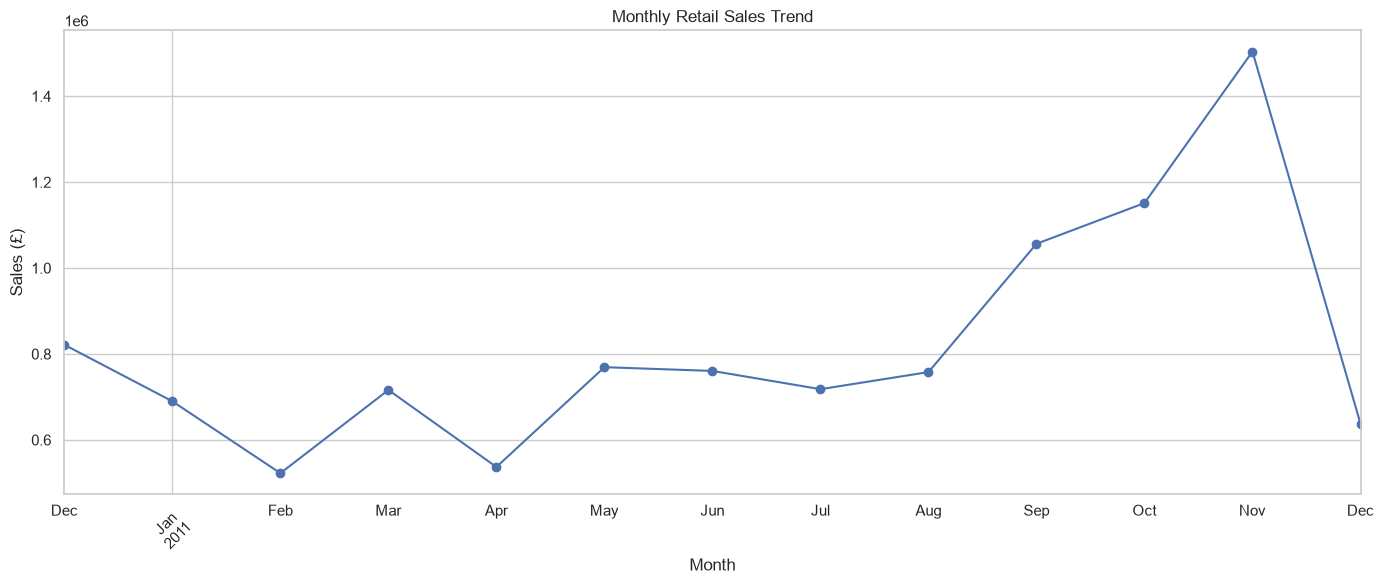

In [16]:
plt.figure(figsize=(14, 6))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (£)")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [17]:
top_products = (
    sales_df.groupby("Description")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Sales Revenue:")
display(top_products)

Top 10 Products by Sales Revenue:


Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Sales, dtype: float64

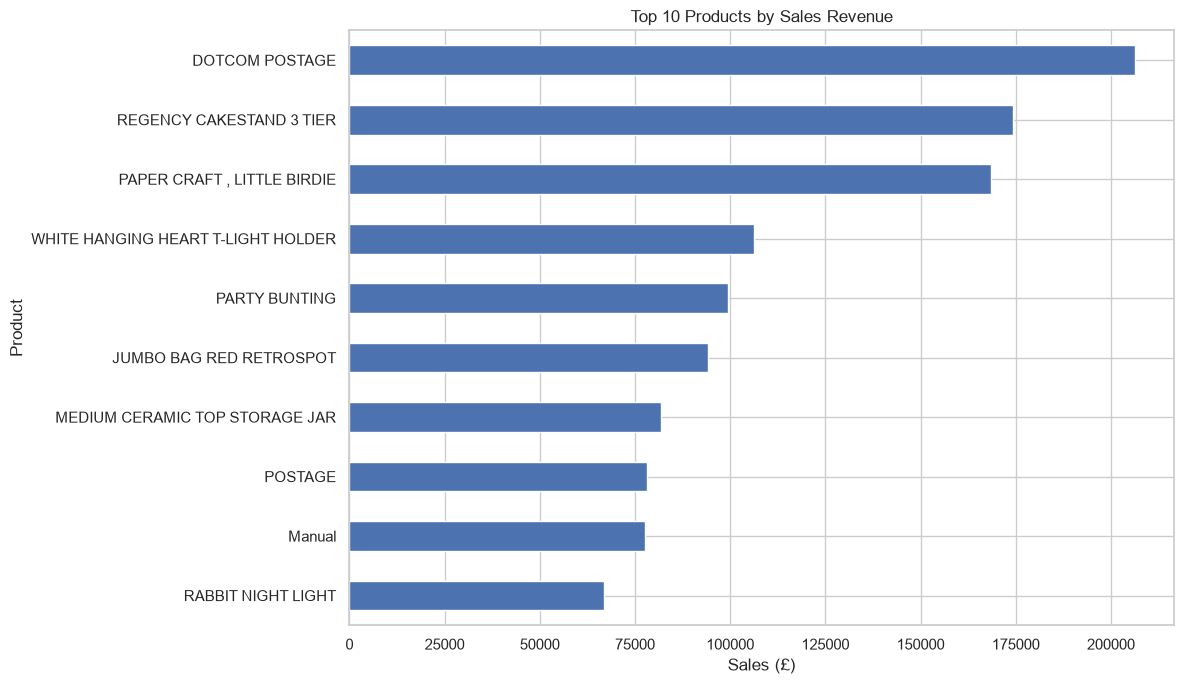

In [18]:
plt.figure(figsize=(12, 7))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Sales Revenue")
plt.xlabel("Sales (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [19]:
country_sales = (
    sales_df.groupby("Country")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Countries by Sales:")
display(country_sales.head(10))

Top 10 Countries by Sales:


Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Sales, dtype: float64

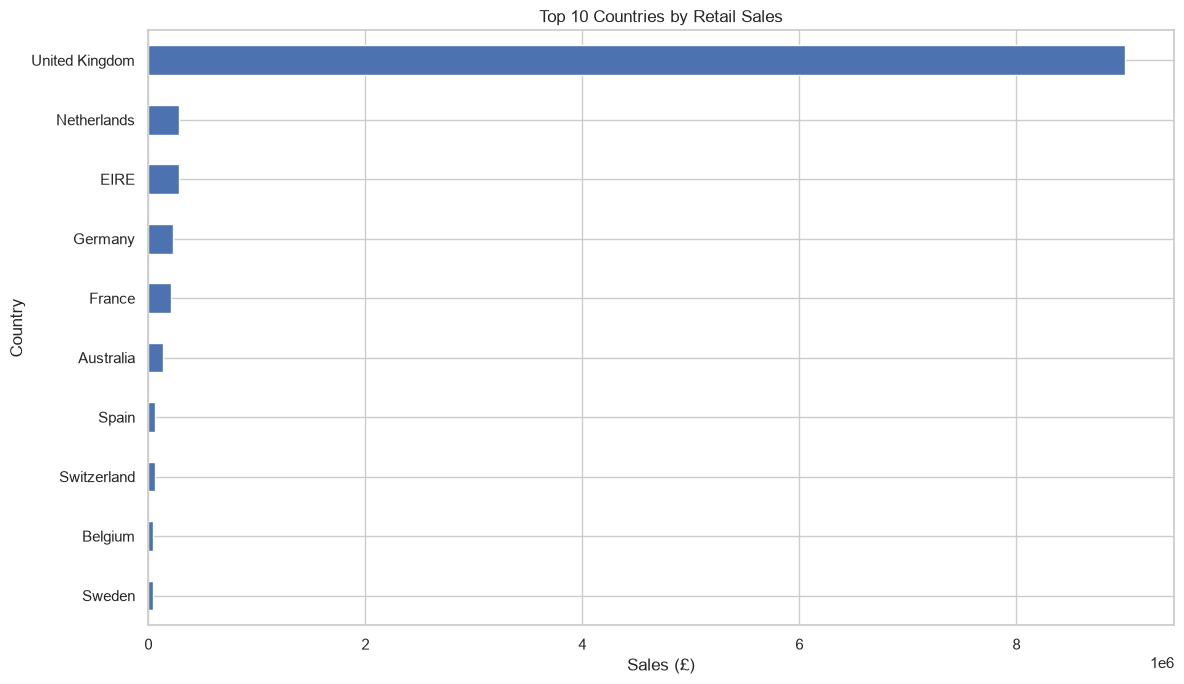

In [20]:
plt.figure(figsize=(12, 7))

country_sales.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Retail Sales")
plt.xlabel("Sales (£)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [21]:
top_quantity_products = (
    sales_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Quantity Sold:")
display(top_quantity_products)

Top 10 Products by Quantity Sold:


Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

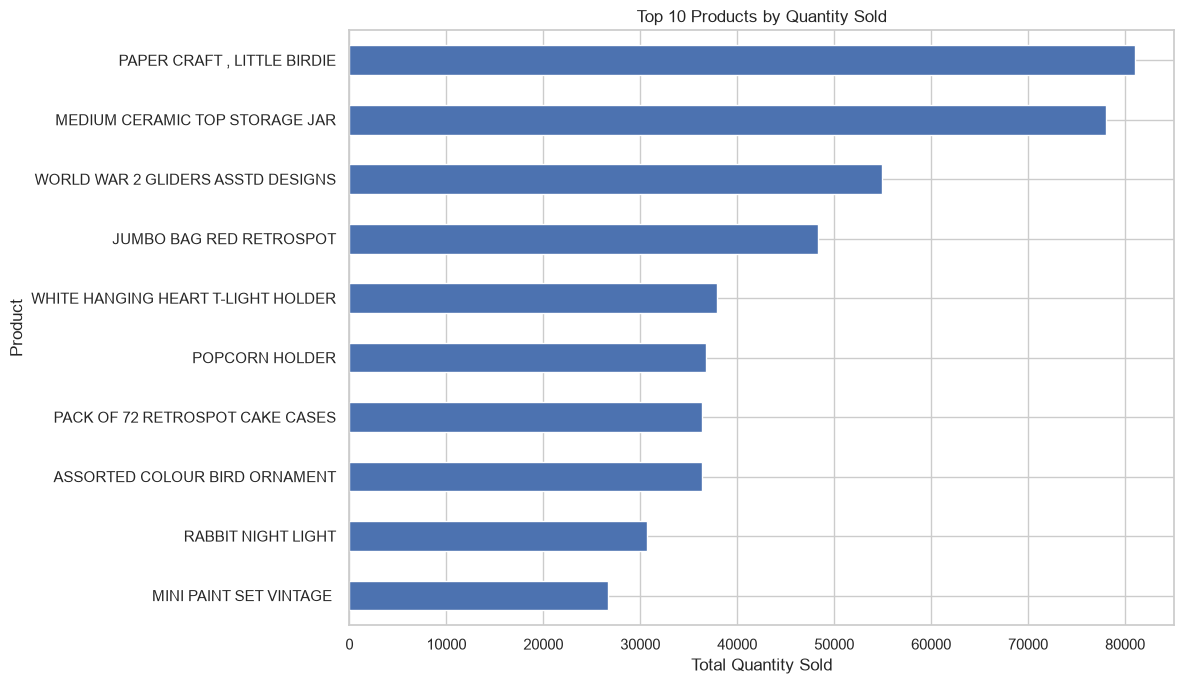

In [22]:
plt.figure(figsize=(12, 7))

top_quantity_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [23]:
sales_df["Hour"] = sales_df["InvoiceDate"].dt.hour

hourly_orders = (
    sales_df.groupby("Hour")["InvoiceNo"]
    .nunique()
)

print("Orders by Hour:")
display(hourly_orders)

Orders by Hour:


Hour
6        1
7       29
8      566
9     1484
10    2361
11    2396
12    3220
13    2753
14    2457
15    2336
16    1335
17     667
18     192
19     146
20      18
Name: InvoiceNo, dtype: int64

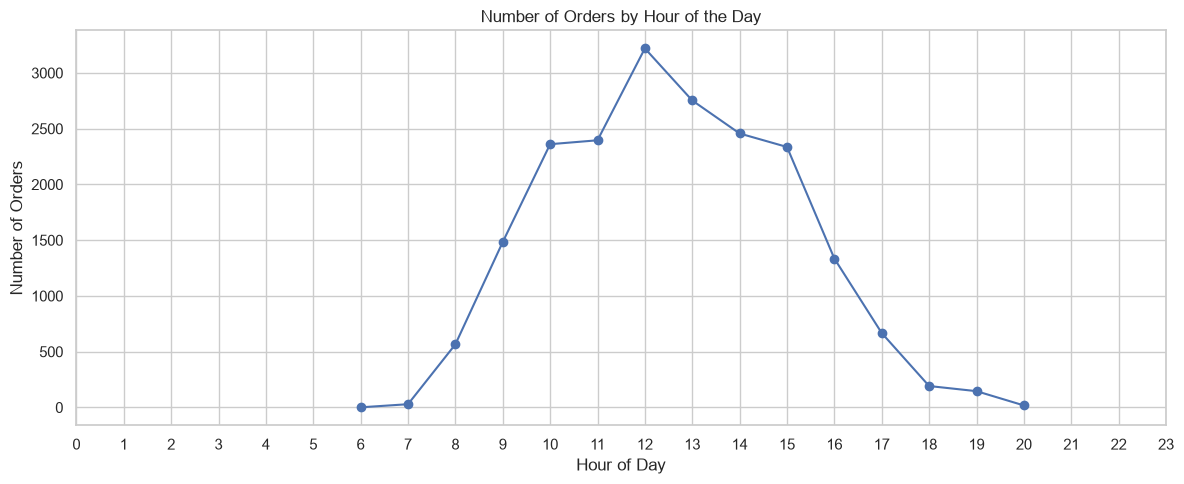

In [24]:
plt.figure(figsize=(12, 5))

hourly_orders.plot(kind="line", marker="o")

plt.title("Number of Orders by Hour of the Day")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Orders")
plt.xticks(range(0, 24))
plt.grid(True)

plt.tight_layout()
plt.show()

In [25]:
customer_sales = (
    sales_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Customers by Total Sales:")
display(customer_sales.head(10))

Top 10 Customers by Total Sales:


CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Sales, dtype: float64

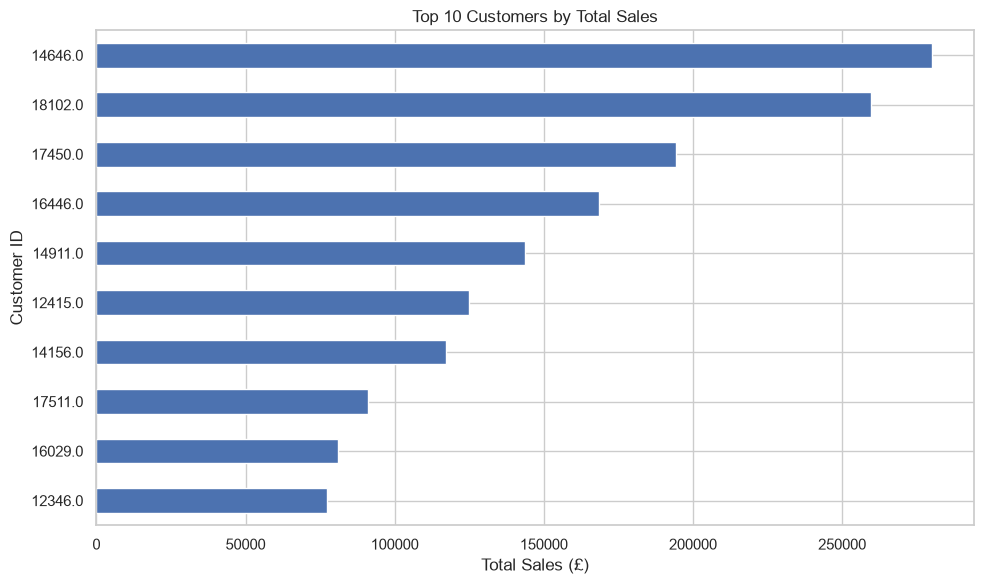

In [26]:
plt.figure(figsize=(10, 6))

customer_sales.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Total Sales")
plt.xlabel("Total Sales (£)")
plt.ylabel("Customer ID")

plt.tight_layout()
plt.show()

In [27]:
cancelled_df = df[
    df["InvoiceNo"].str.startswith("C")
].copy()

print("Cancelled transaction rows:", len(cancelled_df))
print(
    "Unique cancelled invoices:",
    cancelled_df["InvoiceNo"].nunique()
)

Cancelled transaction rows: 9251
Unique cancelled invoices: 3836


In [28]:
returns_df = df[df["Quantity"] < 0].copy()

print("Rows with negative quantities:", len(returns_df))

print(
    "Total negative quantity:",
    returns_df["Quantity"].sum()
)

Rows with negative quantities: 9725
Total negative quantity: -436361


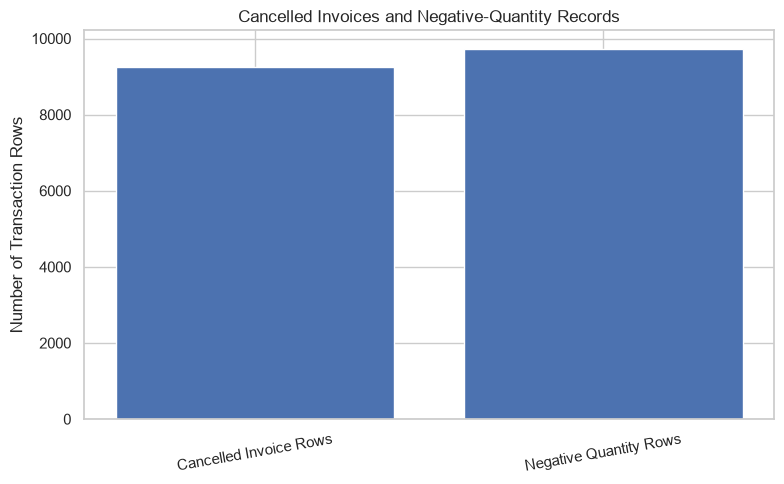

In [29]:
labels = ["Cancelled Invoice Rows", "Negative Quantity Rows"]
values = [len(cancelled_df), len(returns_df)]

plt.figure(figsize=(8, 5))

plt.bar(labels, values)

plt.title("Cancelled Invoices and Negative-Quantity Records")
plt.ylabel("Number of Transaction Rows")
plt.xticks(rotation=10)

plt.tight_layout()
plt.show()

In [30]:
total_sales = sales_df["Sales"].sum()
total_orders = sales_df["InvoiceNo"].nunique()
total_products = sales_df["StockCode"].nunique()
total_customers = sales_df["CustomerID"].nunique()

average_order_value = total_sales / total_orders if total_orders else 0

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Orders",
        "Unique Products",
        "Unique Customers",
        "Average Order Value"
    ],
    "Value": [
        round(total_sales, 2),
        total_orders,
        total_products,
        total_customers,
        round(average_order_value, 2)
    ]
})

display(kpi_summary)

,Metric,Value
0,Total Sales,10642110.80
1,Total Orders,19960.00
2,Unique Products,3922.00
3,Unique Customers,4338.00
4,Average Order Value,533.17


In [31]:
output_file = "Retail_Sales_Analysis_Results.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    kpi_summary.to_excel(
        writer,
        sheet_name="KPIs",
        index=False
    )

    monthly_sales.rename("Sales").to_frame().to_excel(
        writer,
        sheet_name="Monthly Sales"
    )

    top_products.rename("Sales").to_frame().to_excel(
        writer,
        sheet_name="Top Products"
    )

    country_sales.head(10).rename("Sales").to_frame().to_excel(
        writer,
        sheet_name="Top Countries"
    )

    top_quantity_products.rename("Quantity").to_frame().to_excel(
        writer,
        sheet_name="Top Quantities"
    )

    customer_sales.head(10).rename("Sales").to_frame().to_excel(
        writer,
        sheet_name="Top Customers"
    )

print("Analysis results exported successfully!")
print("File:", output_file)

Analysis results exported successfully!
File: Retail_Sales_Analysis_Results.xlsx
